# 05 · Breakdown, sensitivities and extensions

This notebook reports everything the plan declares beyond the confirmatory endpoints:
- the bucket Gains;
- the measurement variants of Table 8.1 (`analysis_plan.md` §8);
- the attribution of the hedging error;
- the exploratory challengers;
- the SPY and Heston extensions (§16).

None of these changes the verdict of notebook 04.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
g = pd.read_csv(R / "2020/gains.csv")
show = lambda variants: g[g.variant.isin(variants) & (g.rule == "R2") & g.base.isin(["R1", "R3", "R4"])][["variant", "cp", "base", "gain", "lo", "hi"]].round(3)
show(["primary", "A", "B", "F", "W36", "W60", "T"])

,variant,cp,base,gain,lo,hi
0,primary,C,R1,0.185,-0.357,0.463
1,primary,C,R3,0.005,-0.207,0.185
2,primary,C,R4,0.040,-0.074,0.163
9,primary,P,R1,0.120,-0.447,0.457
10,primary,P,R3,0.101,-0.112,0.303
11,primary,P,R4,0.182,-0.080,0.319
18,A,C,R1,0.147,-0.399,0.458
19,A,C,R3,0.002,-0.163,0.181
20,A,C,R4,0.037,-0.086,0.180
27,A,P,R1,0.219,-0.547,0.552


**The index level and the window.** Neither moves the picture.
- **A and B** are the options' own level and the vendor's snapshot.
- **W36 and W60** are the longer windows. They give the same point Gains (about 0.18 for calls and 0.14 for puts) with somewhat narrower intervals.
- **The frozen fit F**, fitted once on 2019, does about as well as monthly refitting (calls 0.178 against 0.185; puts 0.145 against 0.120). It is the one variant in which R2 beats both scaling rules for puts. In 2020, refitting monthly did not help: the refits learned March too late.

In [3]:
show(["P-bid", "P-ask", "P-WM", "P-SW", "S3", "V", "OTM", "OTM-refit"])

,variant,cp,base,gain,lo,hi
90,P-bid,C,R1,0.149,-0.246,0.370
91,P-bid,C,R3,0.007,-0.157,0.134
92,P-bid,C,R4,0.036,-0.045,0.119
99,P-bid,P,R1,0.101,-0.317,0.370
100,P-bid,P,R3,0.105,-0.034,0.236
101,P-bid,P,R4,0.137,-0.058,0.240
126,P-ask,C,R1,0.140,-0.247,0.392
127,P-ask,C,R3,-0.002,-0.145,0.144
128,P-ask,C,R4,0.023,-0.068,0.124
135,P-ask,P,R1,0.100,-0.357,0.414


**Marks and populations.**
- **Marks.** Marking at the bid, the ask, the imbalance-weighted mid or Lecture 12's size-weighted price leaves the comparison where it was.
- **Populations.**
  - The spread screen (S3) lowers the point Gains, especially for puts.
  - On the out-of-the-money subsample, Ruf and Wang's home domain, the comparison with the scaling rules stays "not distinguished".
  - Refitting R4 on out-of-the-money pairs makes it almost exactly as good as R2 there (relative Gain about 0).

In [4]:
for col in ("delta_b", "tau_b"):
    t = pd.concat([pd.read_csv(R / f"2020/buckets_{col}_{cp}.csv") for cp in "CP"])
    print(t.round(3).to_string(index=False)); print()

cp  bucket  pairs  G_R2_R1  G_R4_R1  G_R3_R1
 C     0.1  55002    0.147    0.107    0.103
 C     0.2  41943    0.131    0.114    0.115
 C     0.3  41336    0.141    0.123    0.125
 C     0.4  44490    0.165    0.147    0.152
 C     0.5  51376    0.185    0.172    0.180
 C     0.6  54132    0.243    0.233    0.240
 C     0.7  58623    0.262    0.268    0.290
 C     0.8  63062    0.216    0.204    0.281
 C     0.9  79235    0.087   -0.152    0.026
 P     0.1 156343    0.260    0.130    0.100
 P     0.2 101945    0.255    0.168    0.127
 P     0.3  75932    0.232    0.193    0.147
 P     0.4  60691    0.177    0.187    0.150
 P     0.5  49321    0.094    0.132    0.126
 P     0.6  34981    0.042    0.045    0.089
 P     0.7  28266   -0.035   -0.168   -0.016
 P     0.8  25725   -0.130   -0.634   -0.247
 P     0.9  35052   -0.176   -2.021   -0.887

cp  bucket  pairs  G_R2_R1  G_R4_R1  G_R3_R1
 C 123-182  54014    0.162    0.113    0.159
 C   14-30 118537    0.189    0.164    0.199
 C 183-36

## Where the error comes from: the attribution

Each pair's Black–Scholes hedging error is split into vega (ν·Δσ), gamma (½Γ·ΔS²), theta, vanna, volga, carry (rate, dividend and index-timing changes) and a remainder, all divided by S_t. The table shows each term's mean square relative to the mean squared error. `xmom_*` is each term's contribution to the best scalar delta correction.

In [5]:
a = pd.read_csv(R / "2020/attribution.csv")
a[a.group.isin(["all", "stress", "rest"])][["group", "cp", "pairs", "ms_vega", "ms_gamma", "ms_theta", "ms_carry", "ms_vanna", "ms_remainder", "xmom_vega", "xmom_gamma", "xmom_carry"]].round(4)

,group,cp,pairs,ms_vega,ms_gamma,ms_theta,ms_carry,ms_vanna,ms_remainder,xmom_vega,xmom_gamma,xmom_carry
0,all,C,489144,0.5994,0.3355,0.0360,0.0743,0.0588,0.0112,-0.0413,-0.0169,-0.0070
1,all,P,566693,0.6113,0.2658,0.0312,0.0828,0.0445,0.0101,-0.0460,-0.0147,0.0090
34,stress,C,102713,0.6022,0.3723,0.0216,0.0471,0.0693,0.0123,-0.0446,-0.0172,-0.0093
35,stress,P,130732,0.6169,0.2812,0.0183,0.0808,0.0495,0.0107,-0.0499,-0.0150,0.0113
36,rest,C,386431,0.5886,0.1932,0.0915,0.1794,0.0180,0.0068,-0.0303,-0.0160,0.0007
37,rest,P,435961,0.5781,0.1740,0.1076,0.0949,0.0145,0.0064,-0.0297,-0.0134,-0.0011


**Reading.**
- **The vega term is about 60% of the squared error, and the gamma term 27–34%.** The minimum-variance delta works on the vega term: the part of the volatility move that comes with the index move.
- **That part is small, a delta correction of about −0.04** (`xmom_vega`). Most of the vega risk is volatility moving on its own, which no delta can hedge. That caps what any delta rule can gain.
- **The remainder is about 1%,** so the second-order expansion holds even in March 2020: a check on the Greeks.

## Other declared diagnostics

In [6]:
pd.read_csv(R / "2020/extra_diagnostics.csv")

,diagnostic,value
0,A overlap: pairs with <= 10 days left on day two,363.000000
1,"A overlap: of those, whose expiry fed day two'...",0.000000
2,C R0: SSE(WM) - SSE(SW),0.262205
3,C R0: relative to SSE(mid),0.005118
4,"C R0: n*Cov(e,u) / sum(e*u) (1 = mean product ...",0.999309
5,C R1: SSE(WM) - SSE(SW),-0.080124
6,C R1: relative to SSE(mid),-0.020451
7,"C R1: n*Cov(e,u) / sum(e*u) (1 = mean product ...",1.000804
8,P R0: SSE(WM) - SSE(SW),0.399218
9,P R0: relative to SSE(mid),0.003642


**Reading.**
- **The size-weighted marks.** Under the Black–Scholes hedge (R1), the imbalance-weighted mid (WM) has about 2% less squared error than Lecture 12's size-weighted price (SW). Its changes covary negatively with the mid's hedging error, so the 16:00 size imbalance carries a little information, in the direction microstructure theory predicts.
- **Sensitivity A's level never reuses a hedged contract's quotes.** 363 pairs had ten days or less left on day two, and none of their expiries fed that day's fallback level fit.

In [7]:
g[g.variant.isin(["day-two volume > 0", "day-two volume 0 or empty", "primary, block 5", "primary, block 20"]) & (g.rule == "R2") & g.base.isin(["R1", "R4"])][["variant", "cp", "base", "gain", "lo", "hi", "pairs"]].round(3)

,variant,cp,base,gain,lo,hi,pairs
378,day-two volume > 0,C,R1,0.188,-0.326,0.454,397518
380,day-two volume > 0,C,R4,0.054,-0.056,0.171,397518
387,day-two volume > 0,P,R1,0.119,-0.431,0.455,444732
389,day-two volume > 0,P,R4,0.193,-0.062,0.326,444732
396,day-two volume 0 or empty,C,R1,0.177,-0.473,0.487,91681
398,day-two volume 0 or empty,C,R4,0.001,-0.126,0.139,91681
405,day-two volume 0 or empty,P,R1,0.121,-0.497,0.462,123524
407,day-two volume 0 or empty,P,R4,0.148,-0.160,0.297,123524
510,"primary, block 5",C,R1,0.185,-0.356,0.453,489199
512,"primary, block 5",C,R4,0.040,-0.091,0.160,489199


In [8]:
g[(g.variant == "primary") & g.rule.isin(["R5", "R6"])][["cp", "rule", "base", "gain", "lo", "hi"]].round(3)

,cp,rule,base,gain,lo,hi
7,C,R5,R1,0.186,-0.356,0.463
8,C,R6,R1,0.164,-0.327,0.392
16,P,R5,R1,0.115,-0.453,0.453
17,P,R6,R1,-0.034,-0.555,0.305


In [9]:
print(pd.read_csv(R / "2020/mean_error_by_gap.csv").round(6).to_string(index=False))
for cp in "CP":
    print(cp, pd.read_csv(R / f"2020/ljungbox_{cp}.csv").round(4).to_string(index=False))

 gap        R0        R1        R2        R3        R4        R5        R6 variant
   1  0.000282  0.000423  0.000479  0.000464  0.000471  0.000480  0.000485       T
   3  0.001610  0.000862  0.000858  0.000900  0.000793  0.000852  0.000849       T
   4 -0.000706 -0.000186 -0.000492 -0.000375 -0.000377 -0.000491 -0.000483       T
   1  0.000015  0.000156  0.000211  0.000197  0.000203  0.000211  0.000217 primary
   3  0.001346  0.000598  0.000599  0.000635  0.000534  0.000593  0.000590 primary
   4 -0.000933 -0.000412 -0.000722 -0.000601 -0.000607 -0.000721 -0.000713 primary
C  Unnamed: 0  lb_stat  lb_pvalue cp
          5  30.9621        0.0  C
         10  55.3720        0.0  C
P  Unnamed: 0  lb_stat  lb_pvalue cp
          5  56.7213        0.0  P
         10 103.3875        0.0  P


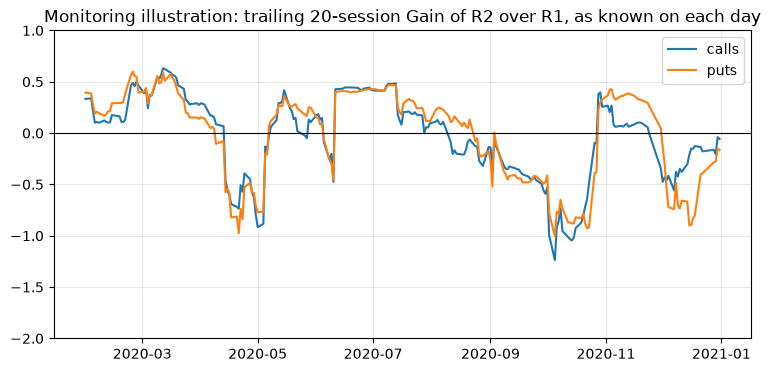

In [10]:
mon = pd.read_csv(R / "2020/monitoring.csv", parse_dates=["session"])
fig, ax = plt.subplots()
for cp in "CP":
    x = mon[mon.cp == cp]
    ax.plot(x.session, x.trailing20_gain_known, label=f"{'calls' if cp == 'C' else 'puts'}")
ax.axhline(0, color="k", lw=0.8); ax.set_ylim(-2, 1)
ax.set_title("Monitoring illustration: trailing 20-session Gain of R2 over R1, as known on each day")
ax.legend()

**The monitoring illustration** shows what a desk would have seen: the trailing 20-session Gain, computed only from completed hedges. It first turns negative on 9 April (puts) and 14 April (calls), about four weeks after the worst days of mid-March, so it would have flagged the problem only partway through April. Per the plan, no switching rule is evaluated.

## Exploratory challengers: a regression tree (R7) and gradient boosting (R8)

In [11]:
g[g.variant.str.startswith("learners")][["cp", "rule", "base", "gain", "lo", "hi"]].round(3)

,cp,rule,base,gain,lo,hi
546,C,R7,R2,0.022,-0.140,0.159
547,C,R2,R1,0.185,-0.357,0.463
548,C,R8,R2,-0.023,-0.186,0.151
549,C,R8,R7,-0.046,-0.305,0.129
550,P,R7,R2,-0.214,-0.548,0.080
551,P,R2,R1,0.120,-0.447,0.457
552,P,R8,R2,-9.249,-17.357,-0.185
553,P,R8,R7,-7.446,-11.485,-0.023


In [12]:
pd.read_csv(R / "2020/smoothness.csv").round(4)

,rule,adjacent_pairs,out_of_order_share,mean_daily_abs_change
0,h_R1,1042891,0.0175,0.0344
1,h_R2,1042891,0.0175,0.0333
2,h_R7,1042891,0.0179,0.0389
3,h_R8,1042891,0.0283,0.0493


**Reading.**
- **The depth-3 tree (R7)** is not distinguished from Hull–White.
- **The boosted correction (R8) failed badly for puts.** It was tuned on 2019, when the trailing 20-day realized volatility never exceeded 31% and the worst 5-day return was −6%. In March 2020 those features reached 98% and −20%, far outside what the trees had seen, and their extreme leaves pushed the median put hedge ratio from −0.57 to −1.07. March's squared error was 13 times R2's; in every other month R8 tracked R2.
- **It is also rougher.** It has more out-of-order hedge ratios across adjacent strikes (2.8% against 1.8%) and 48% more daily turnover.

That is the failure mode the non-smooth-hedge argument predicts: a flexible learner extrapolates arbitrarily outside its training data.

## SPY (§16.1)

The same protocol on SPY: American options (Lecture 12's tree for puts), SPY's own close, and distributions added to the hedge leg on ex-dates.

In [13]:
s = pd.read_csv(R / "spy/gains.csv")
s[(s.rule == "R2") & s.base.isin(["R1", "R3", "R4"])][["variant", "cp", "base", "gain", "lo", "hi", "pairs"]].round(3)

,variant,cp,base,gain,lo,hi,pairs
0,primary,C,R1,0.103,-0.276,0.379,516213
1,primary,C,R3,0.061,-0.017,0.180,516213
2,primary,C,R4,0.044,-0.084,0.197,516213
8,primary,P,R1,0.246,-0.241,0.467,504482
9,primary,P,R3,0.052,-0.211,0.197,504482
10,primary,P,R4,0.054,-0.121,0.151,504482
16,ex-date pairs only,C,R1,-0.573,NaN,NaN,6122
17,ex-date pairs only,P,R1,-0.687,NaN,NaN,6547
18,B,C,R1,0.122,-0.307,0.377,516213
19,B,C,R3,0.054,-0.013,0.153,516213


**Reading.**
- **SPY tells the same story.** The point Gains are positive (0.10 for calls, 0.25 for puts), the intervals span zero, and the scaling rules are not distinguished.
- **The ex-date-only rows are too thin to read.** 2020 has three ex-dates with pairs, so most bootstrap draws contain none and the interval is undefined.
- **On ex-date pairs, adding the distribution to the hedge leg helps puts but not calls.** That is the limitation stated in advance: calls are priced as European. A deep in-the-money American call carries an early-exercise premium before the ex-date, which vanishes on it.

## Heston (§16.2), in the style of Lecture 12

Heston's model makes the variance v a second random factor, correlated (ρ) with the index (Lecture 12).
- **Calibration.** Each session is calibrated with `scipy.optimize.least_squares`, as in the lecture. **L** fits the lecture's own sample (calls 50–100 days, sizes above 10, the size-weighted price), to price errors and to implied-volatility errors. **B** is a broader fit to out-of-the-money calls and puts, 14 days to a year.
- **Hedging.** The Heston minimum-variance delta, C_S + (ρξ/S)·C_v, is the model's own version of Hull and White's correction. It is compared with the Black–Scholes and Hull–White deltas on the 2020 pairs.

In [14]:
p = pd.read_csv(R / "heston/params.csv", parse_dates=["session"])
p.groupby("fit").agg(sessions=("session", "size"), ok=("ok", "mean"), iv_rmse_median=("iv_rmse", "median"),
                     rho_median=("rho", "median"), xi_median=("xi", "median"), kappa_median=("kappa", "median")).round(4)

,sessions,ok,iv_rmse_median,rho_median,xi_median,kappa_median
fit,,,,,,
B-iv,497,0.9014,0.0187,-0.6497,2.7974,10.0000
L-iv,497,0.9980,0.0035,-0.7355,1.3900,3.7806
L-price,497,0.9980,0.0041,-0.7542,1.2104,3.5189


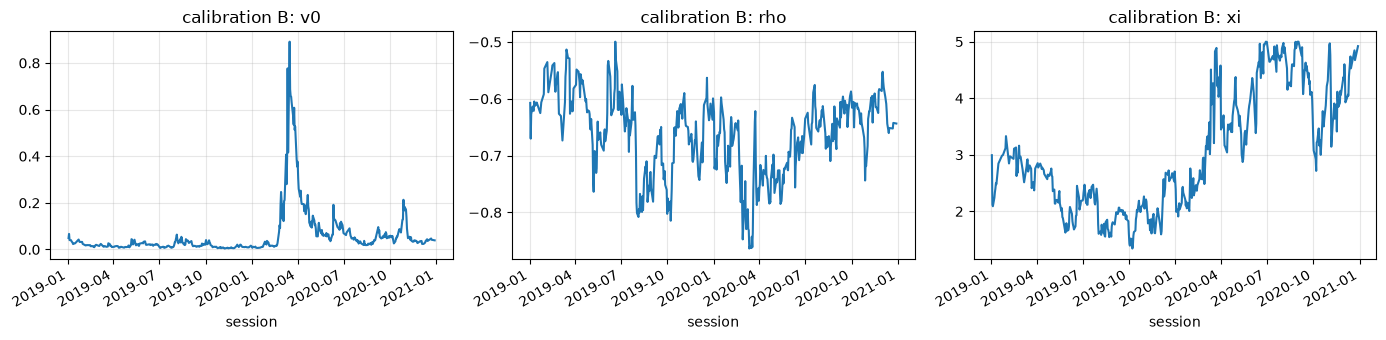

In [15]:
b = p[(p.fit == "B-iv") & p.ok.fillna(False).astype(bool)].set_index("session")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, ["v0", "rho", "xi"]):
    b[c].plot(ax=ax, title=f"calibration B: {c}")
plt.tight_layout()

In [16]:
pd.read_csv(R / "heston/gains.csv").round(3)

,cp,rule,base,gain,lo,hi,p_plus,p_minus,pairs,sample,sessions
0,C,H_model,R1,-1.304,-1.806,-0.727,1.000,0.000,447707,all converged fits,227
1,C,H_mv,R1,0.035,-0.639,0.317,0.478,0.522,447707,all converged fits,227
2,C,R2,R1,0.195,-0.352,0.470,0.232,0.768,447707,all converged fits,227
3,C,H_mv,R2,-0.198,-0.457,-0.125,1.000,0.000,447707,all converged fits,227
4,C,H_mv,H_model,0.581,0.093,0.748,0.008,0.992,447707,all converged fits,227
5,P,H_model,R1,-1.109,-1.723,-0.444,1.000,0.000,521744,all converged fits,227
6,P,H_mv,R1,0.020,-0.563,0.308,0.477,0.524,521744,all converged fits,227
7,P,R2,R1,0.127,-0.436,0.467,0.301,0.699,521744,all converged fits,227
8,P,H_mv,R2,-0.122,-0.388,-0.010,0.987,0.013,521744,all converged fits,227
9,P,H_mv,H_model,0.536,-0.021,0.738,0.028,0.972,521744,all converged fits,227


**Reading** (`H_model`: the Heston model delta C_S; `H_mv`: the Heston minimum-variance delta):
- **The calibrations.**
  - The lecture's fit (L, 50–100-day calls) converges on 99.8% of sessions, with errors of 0.35–0.41 vol points.
  - The broad fit (B, out-of-the-money calls and puts, 14 days to a year) converges on 90%, with a median error of 1.9 vol points. Three-quarters of its fits put κ at the bound of 10: Heston strains to fit SPX's skew across maturities.
  - Through March 2020, v₀ rises to 0.3–0.9 (55–95% volatility) and ρ stays near −0.8.
- **The Heston model delta is far worse than Black–Scholes,** roughly doubling the squared error (Gains −1.30 and −1.11). As calibrated, Heston implies a smile that moves with the index (close to sticky delta), so its delta over-hedges calls and under-hedges puts.
- **Heston's minimum-variance delta repairs most of that,** through its ρξ·C_v/S term, and ends level with Black–Scholes (Gains +0.04 and +0.02, intervals spanning zero).
- **It is significantly worse than Hull and White's empirical rule:** −0.20 [−0.46, −0.13] for calls and −0.12 [−0.39, −0.01] for puts. This matches Hull and White's comparison with SABR: a correction estimated from historical co-movement beats one read off each day's smile.
- **The 57 sessions whose fits hit no bound.** For calls the ordering is the same: the Heston minimum-variance delta is worse than R2, −0.05 [−0.35, −0.01]. For puts, the model delta, the minimum-variance delta and R2 cannot be told apart, and all are below Black–Scholes on those days. Those sessions are not a random subset: a fit without bound hits is a day on which Heston happens to fit well.